## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.

> **Laboratorio aplicado:** *Conectando una protoboard con la menor cantidad de cable* (Árbol de Expansión Mínimo con el algoritmo de Kruskal).

In [ ]:
# @title Ingrese datos
nombre_estudiante = "Jerónimo Urrego, Daniel Cardenas, Andrés Rubio" # @param {"type":"string"}
carnet =  # @param {"type":"integer"}

## 1) Descripción del problema **[1 pts]**

Un equipo de electrónica diseña un prototipo sobre una **protoboard simplificada** de **30 columnas (1 a 30)** y **10 filas (A a J)**. Sobre ella se ubican **7 componentes** que deben quedar conectados entre sí:

| Componente | Identificador | Posición |
|---|---|---|
| Fuente de alimentación | F | A3 |
| LED | L | C8 |
| Sensor | S | B16 |
| Pulsador | P | D24 |
| Buzzer | B | H6 |
| Potenciómetro | R | I15 |
| Microcontrolador | M | G25 |

**Problema:** ¿cuál es el conjunto de cables que conecta **todos** los componentes usando la **menor longitud total de cable**?

**Modelado con grafos**

- Cada componente es un **vértice** (7 vértices).
- Cada posible cable entre dos componentes es una **arista** (grafo completo: $\binom{7}{2}=21$ aristas).
- El **peso** de la arista es la longitud del cable: la distancia
  $d = |columna_1 - columna_2| + |fila_1 - fila_2|$, con las filas $A=1, B=2, \dots, J=10$.
  Ejemplo: $F=A3=(3,1)$ y $L=C8=(8,3)$ → $d = |3-8| + |1-3| = 7$.
- La solución es un **Árbol de Expansión Mínimo (MST)**: $n-1 = 6$ aristas que conectan todos los vértices, sin ciclos y con la suma de pesos mínima. Se obtiene con el **algoritmo de Kruskal** implementado manualmente (sin librerías que calculen el MST).

Al final (Punto 6) el Buzzer se mueve de **H6 a J20**, se recalcula todo y se responde si la cantidad total de cable **aumentó o disminuyó**.

*Para este laboratorio no se evalúa el funcionamiento electrónico del circuito: la protoboard es solo una representación espacial del problema.

## 2) Requerimientos **[2 pts]**

Lista requerimientos **funcionales** y **no funcionales**.

### Requerimientos funcionales

1. Dibujar la protoboard (columnas 1–30, filas A–J) y ubicar los 7 componentes en sus posiciones, mostrando filas, columnas, posición e identificador de cada elemento. 
2. Representar cada componente como un vértice y cada posible cable como una arista. 
3. Calcular automáticamente la distancia entre cada par de componentes: $|col_1-col_2|+|fila_1-fila_2|$ (A=1 … J=10). No se escriben pesos a mano. 
4. Mostrar gráficamente todas las posibles conexiones con su peso (21 para 7 componentes). 
5. Ordenar las conexiones de menor a mayor peso. 
6. Implementar manualmente Kruskal: tomar la conexión de menor peso, evitar ciclos y continuar hasta conectar todos los componentes. 
7. Garantizar que el árbol final tenga exactamente $n-1$ aristas (6 para 7 componentes) y conecte todos los componentes. 
8. Mostrar el resultado: componentes, cables seleccionados, longitud de cada cable y longitud total. 
9. Dibujar la protoboard con el cableado obtenido para comparar visualmente con la distribución original. 
10. Mover un componente (Buzzer H6 → J20), actualizar el grafo automáticamente, recalcular el MST, volver a graficar e indicar si la longitud total aumentó o disminuyó. 
### Requerimientos no funcionales

1. Restricción de librerías no usar librerías que calculen el MST directamente (p. ej. `networkx`); solo Python estándar y `matplotlib` para graficar. |
2. Ejecutable: el notebook debe correr de principio a fin sin errores y generar los gráficos desde el propio notebook. 
3. Eficiencia: complejidad $O(E\log E)$ con $E = n(n-1)/2$, es decir $O(n^2\log n)$; con $n=7$ responde al instante. 
4. Corrección: el peso total del árbol debe ser siempre el mínimo y el resultado debe ser reproducible (ante pesos iguales se conserva el orden de generación). 
5. Robustez: validar las posiciones (fila A–J, columna 1–30), rechazar dos componentes en la misma posición y avisar si el grafo no es conexo. 
6. Claridad: código dividido en funciones pequeñas, con nombres en español y comentarios. 
7. Legibilidad visual: gráficos con ejes rotulados, leyenda, colores distinguibles y pesos visibles.
8. Verificabilidad: pruebas con `assert`. 

## 3) Historias de usuario **[2 pts]**
Escribe 3–5 historias de usuario con el formato visto en clase:
Incluye criterios de aceptación.


**HU1 – Visualizar la protoboard**
- **Como** encargado del montaje, **quiero** ver gráficamente la protoboard con los siete componentes en sus posiciones, **para** verificar que la distribución inicial es la correcta.
- **Criterios de aceptación:**
  1. Se muestran las columnas 1–30 y las filas A–J.
  2. Cada componente aparece en su posición (F=A3, L=C8, S=B16, P=D24, B=H6, R=I15, M=G25) con su identificador.
  3. El gráfico se genera desde el notebook.

**HU2 – Conocer el cable necesario para cada conexión**
- **Como** ingeniero electrónico, **quiero** que el programa calcule automáticamente la distancia entre cada par de componentes, **para** saber cuánto cable requiere cada conexión posible.
- **Criterios de aceptación:**
  1. Se usa $d=|col_1-col_2|+|fila_1-fila_2|$ con A=1 … J=10.
  2. Se generan las 21 conexiones posibles y cada una muestra su peso (p. ej. F–L = 7).
  3. Ningún peso se escribe a mano.

**HU3 – Obtener el cableado de menor longitud**
- **Como** ingeniero electrónico, **quiero** obtener el conjunto de cables que conecta todos los componentes con la menor longitud total, **para** ahorrar material y simplificar el montaje.
- **Criterios de aceptación:**
  1. Se aplica Kruskal implementado manualmente (sin librerías que calculen el MST).
  2. El resultado tiene exactamente 6 cables, sin ciclos, y conecta los 7 componentes.
  3. La longitud total es la mínima posible (se comprueba contra fuerza bruta).

**HU4 – Revisar el resultado sobre la protoboard**
- **Como** encargado del montaje, **quiero** ver la lista de cables elegidos con su longitud y la longitud total, junto con la protoboard cableada, **para** comparar visualmente la distribución original con el cableado obtenido.
- **Criterios de aceptación:**
  1. Se imprime «Cable k: X - Y = longitud» para cada cable y «Longitud total de cable».
  2. Se muestran en la misma figura la protoboard original y la cableada.

**HU5 – Evaluar el cambio de posición de un componente**
- **Como** encargado del montaje, **quiero** mover el Buzzer de H6 a J20 y que el programa recalcule el grafo y el MST, **para** saber si el cable total aumenta o disminuye.
- **Criterios de aceptación:**
  1. La posición del Buzzer se actualiza y las distancias se recalculan automáticamente.
  2. Se muestran «MST original: longitud total» y «MST después del cambio: longitud total».
  3. Se genera de nuevo la gráfica con las nuevas conexiones y se indica si el cable aumentó o disminuyó.

## 4) Diagramas de flujo **[5 pts]**
Incluye el diagrama que muestre el proceso general

Adjunta imagen y descríbelo claramente.

### Diagrama de flujo del proceso general

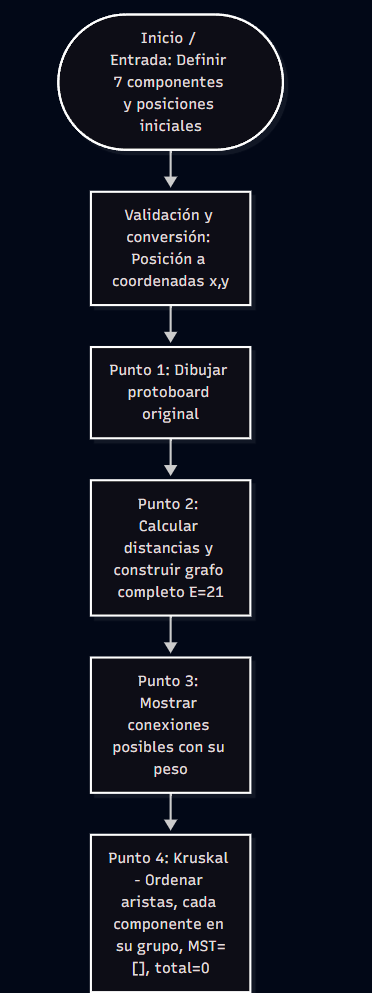

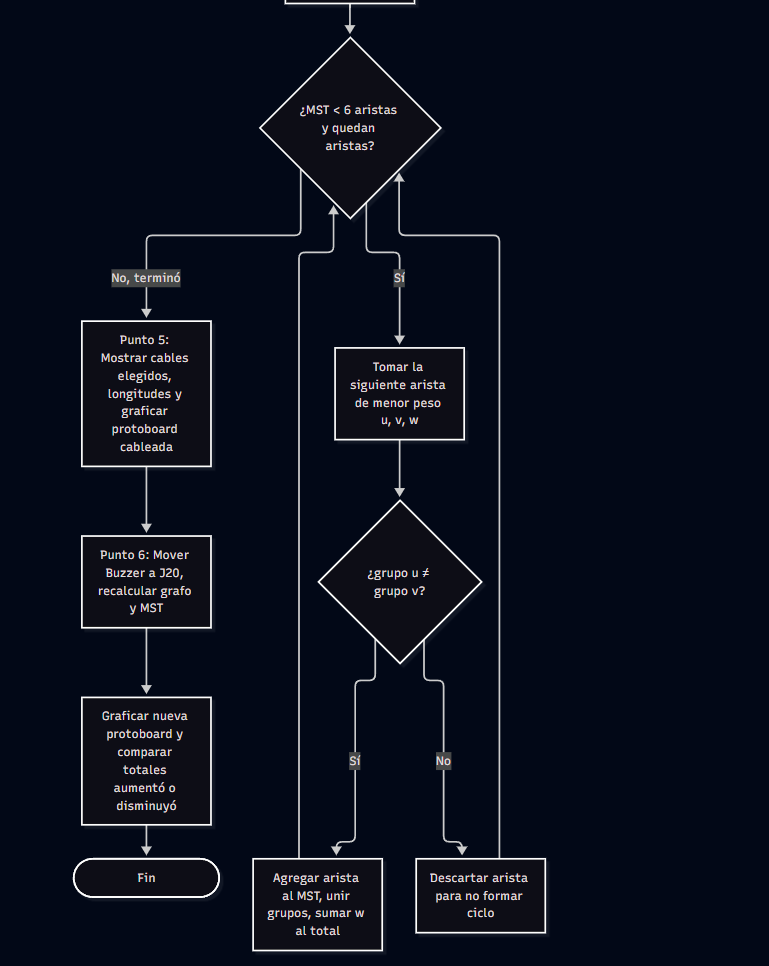

### Descripción del diagrama

El diagrama muestra el proceso general de la solución, de arriba hacia abajo:

1. **Inicio / Entrada:** se definen los 7 componentes con sus posiciones iniciales (F=A3, L=C8, S=B16, P=D24, B=H6, R=I15, M=G25).
2. **Validación y conversión:** cada posición (letra + número) se valida y se convierte a coordenadas `(columna, fila)` con A=1 … J=10.
3. **Punto 1:** se dibuja la protoboard con filas, columnas, posiciones e identificadores.
4. **Punto 2:** se calcula la distancia entre todos los pares de componentes y así se construye el grafo completo con $E=n(n-1)/2=21$ aristas.
5. **Punto 3:** se muestran todas las conexiones posibles con su peso.
6. **Punto 4 – Kruskal:**
   - se ordenan las aristas de menor a mayor peso;
   - cada componente empieza en su propio grupo, con `MST = []` y `total = 0`;
   - **bucle:** mientras el MST tenga menos de $n-1$ aristas y queden aristas, se toma la siguiente de menor peso `(u, v, w)`. Si `grupo(u) ≠ grupo(v)` no se forma ciclo: se agrega la arista al MST, se unen los grupos y se suma `w` al total. Si los dos extremos ya están en el mismo grupo, la arista se descarta porque formaría un ciclo;
   - cuando el MST llega a $n-1=6$ aristas el bucle termina.
7. **Punto 5:** se muestran los cables elegidos, la longitud de cada uno y la longitud total, y se grafica la protoboard con el cableado junto a la original.
8. **Punto 6:** se mueve el Buzzer de H6 a J20, se recalcula todo (grafo y MST), se grafica de nuevo y se comparan los totales para decir si el cable **aumentó o disminuyó**.
9. **Fin.**


### 5) Análisis de complejidad **[15 pts]**
Incluye:
- Justificación
- Función T[n]
- Mejor y peor caso con gráfica

### 5.1 Justificación

Sea **n** el número de componentes (vértices) y **E = n(n−1)/2** el número de aristas del grafo completo (para n = 7, E = 21).

| Etapa | Qué hace | Costo |
|---|---|---|
| Convertir posiciones | recorrer los n componentes | $O(n)$ |
| Construir el grafo | doble ciclo: una distancia (operación simple) por cada par | $E$ operaciones → $O(n^2)$ |
| Ordenar las aristas | ordenamiento por comparación de E elementos | $O(E\log E)$ |
| Bucle de Kruskal | por cada arista revisada, una comparación de grupos ($O(1)$). Si se acepta, hay que **unir los grupos** recorriendo los n componentes ($O(n)$); esto ocurre exactamente $n-1$ veces | $k + (n-1)\cdot n$, con $k$ = aristas revisadas |

Como $E=\Theta(n^2)$, se cumple $\log E = \log\frac{n(n-1)}{2} = 2\log n + O(1) = \Theta(\log n)$.

### 5.2 Función T[n]

Con constantes $c_1,\dots,c_4>0$ (costo de cada operación simple):

$$T(n) = c_1\,E \;+\; c_2\,E\log_2 E \;+\; c_3\,k(n) \;+\; c_4\,n(n-1), \qquad E=\frac{n(n-1)}{2}$$

El único término que depende de los **datos** (de los pesos) es $k(n)$, el número de aristas revisadas por el bucle antes de completar el árbol.

- **Mejor caso:** las $n-1$ aristas más livianas ya forman un árbol que conecta todo, así que el bucle se detiene tras $k_{mejor}=n-1$ revisiones:

$$T_{mejor}(n) = c_1\frac{n(n-1)}{2} + c_2\frac{n(n-1)}{2}\log_2\frac{n(n-1)}{2} + c_3(n-1) + c_4\,n(n-1) = \Theta(n^2\log n)$$

- **Peor caso:** la arista que conecta al último vértice es la más pesada de las necesarias, así que hay que revisar casi todas: $k_{peor}=E-(n-1)+1=E-n+2$ (en un grafo completo no puede ser la última de todas, porque cada vértice tiene varias aristas):

$$T_{peor}(n) = c_1\frac{n(n-1)}{2} + c_2\frac{n(n-1)}{2}\log_2\frac{n(n-1)}{2} + c_3\left(\frac{n(n-1)}{2}-n+2\right) + c_4\,n(n-1) = \Theta(n^2\log n)$$

- **Conclusión:** el término dominante es el ordenamiento $E\log_2E$, igual en ambos casos, así que el algoritmo es $\Theta(n^2\log n)$ en el mejor y en el peor caso. La diferencia está en el bucle: **lineal** en el mejor caso ($n-1$ revisiones) y **cuadrático** en el peor ($\approx n^2/2$).
- **Complejidad espacial:** $O(E)=O(n^2)$ para la lista de aristas (más $O(n)$ para los grupos).
- **Caso del laboratorio ($n=7$):** $E=21$ y entre $k=6$ y $k=16$ revisiones.

### 5.3 Mejor y peor caso con gráfica

Cada imagen muestra, para su caso, a la izquierda las **aristas revisadas** por el bucle de Kruskal (la línea es la fórmula y los puntos son lo que midió el `kruskal` del notebook) y a la derecha la **función T(n)** junto con su término dominante $E\log_2E$.

#### Mejor caso: $k = n-1$

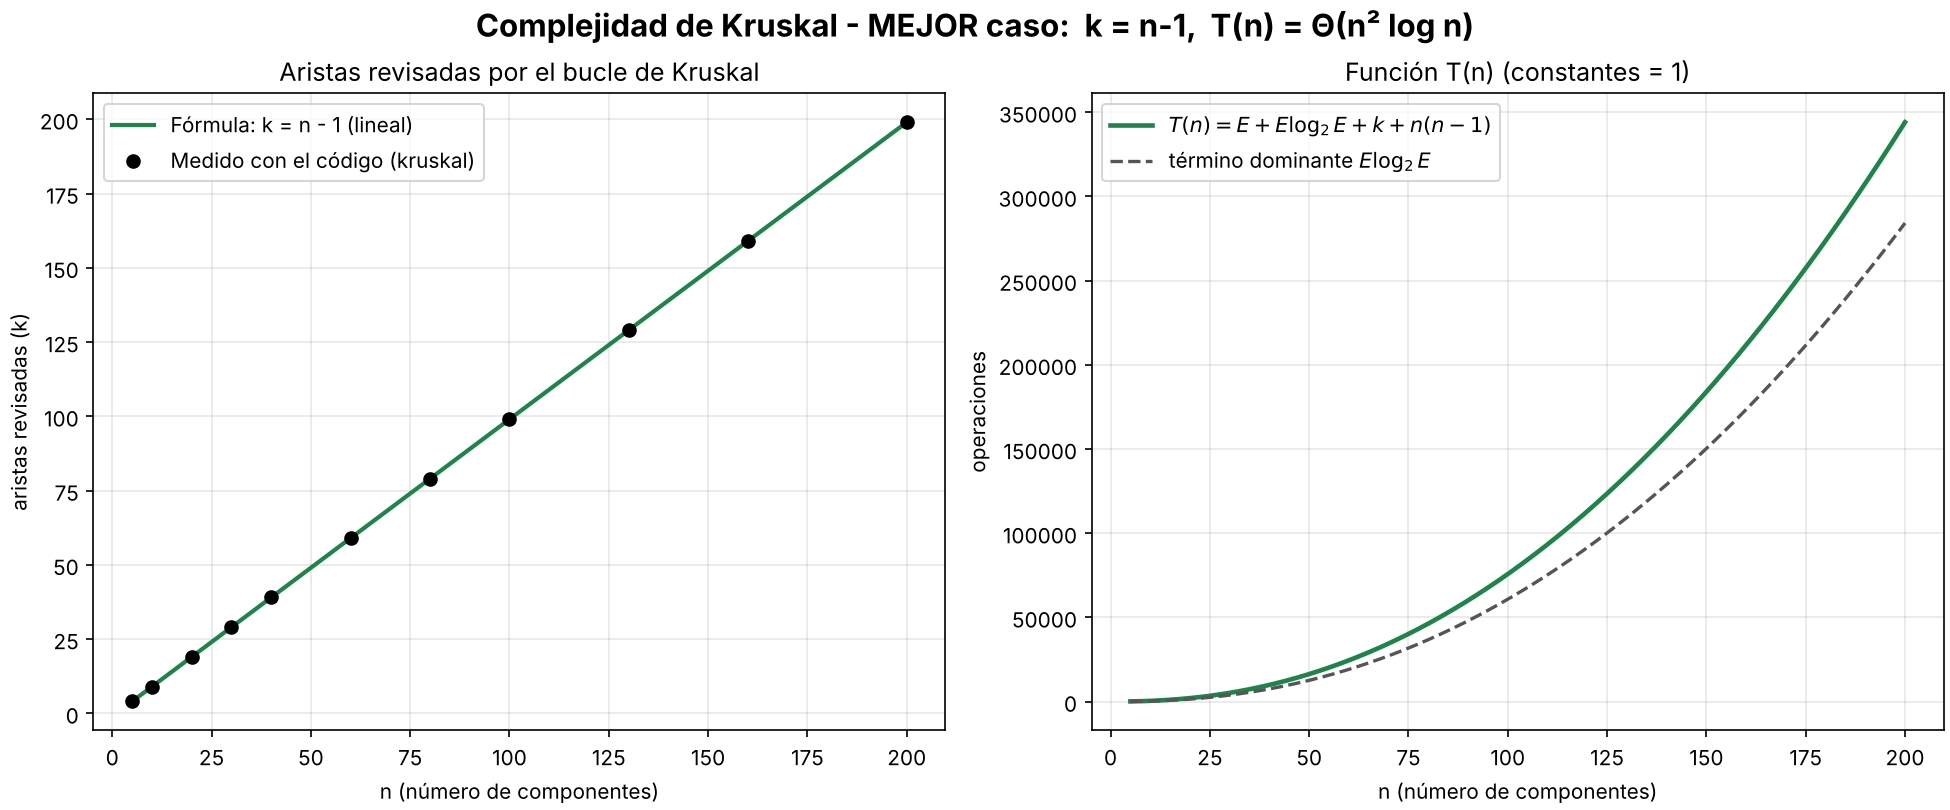

- Las $n-1$ aristas más livianas ya forman el árbol, así que el bucle se detiene tras $n-1$ revisiones: **crece de forma lineal** (izquierda).
- $T_{mejor}(n)$ queda apenas por encima del ordenamiento $E\log_2E$, que es lo que domina: $T_{mejor}(n)=\Theta(n^2\log n)$.

#### Peor caso: $k = E-n+2$

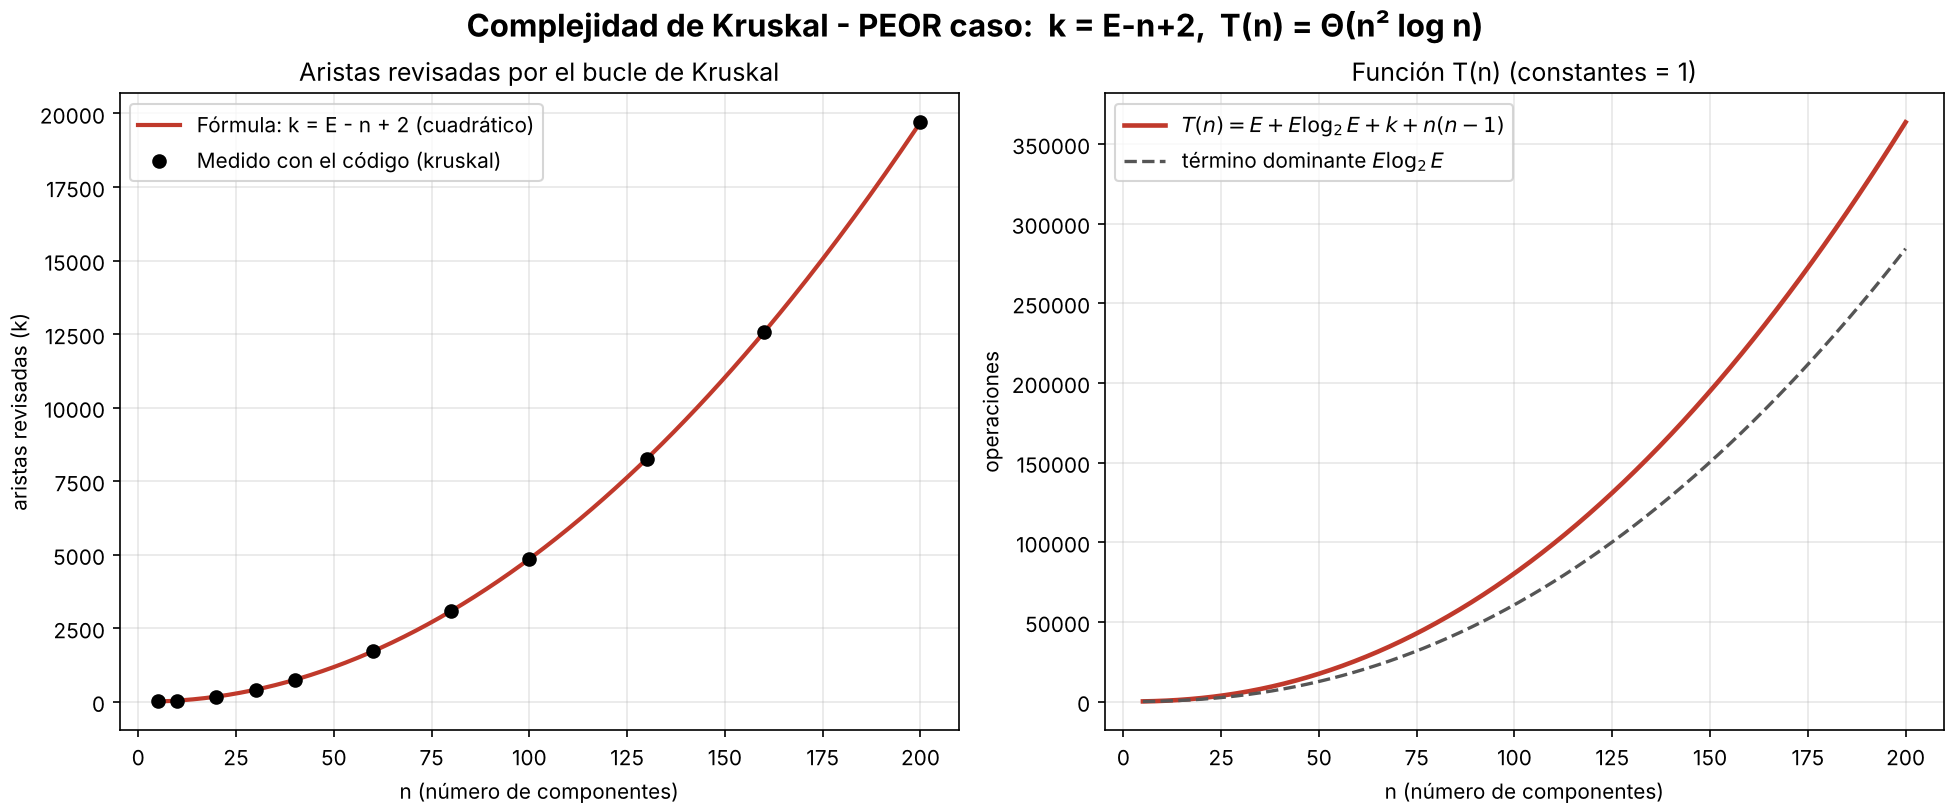

- Hay que revisar casi todas las aristas antes de encontrar la que conecta al último vértice: **crece de forma cuadrática** (izquierda).
- $T_{peor}(n)$ también sigue de cerca a $E\log_2E$, solo que con un término extra del bucle: $T_{peor}(n)=\Theta(n^2\log n)$.

#### Comparación

| | Aristas revisadas $k$ | $T(n)$ |
|---|---|---|
| Mejor caso | $n-1$ → $\Theta(n)$ | $\Theta(n^2\log n)$ |
| Peor caso | $E-n+2$ → $\Theta(n^2)$ | $\Theta(n^2\log n)$ |

En ambos casos el costo total lo domina el ordenamiento de las aristas; la diferencia entre mejor y peor caso está en cuántas aristas hay que revisar. Para el laboratorio ($n=7$, $E=21$) el mejor caso serían 6 revisiones y el peor 16; el algoritmo real revisó 7 (se comprueba en la sección 6.5). Espacio: $O(n^2)$.

## 6) Código funcional **[15 pts]**
Incluye tu implementación completa.

No pegues código incompleto; debe ser ejecutable.

Solo se usa la librería estándar de Python y `matplotlib` (para graficar). **No** se usa ninguna librería que calcule el MST: Kruskal está implementado a mano.

### 6.1 Datos y conversión de posiciones

In [2]:
import math
import time
import random
from itertools import combinations
import matplotlib.pyplot as plt

# ---------- Datos del problema ----------
columnas = 30
filas = "ABCDEFGHIJ"          # A = 1, B = 2, ..., J = 10

nombres = {
    "F": "Fuente de alimentación",
    "L": "LED",
    "S": "Sensor",
    "P": "Pulsador",
    "B": "Buzzer",
    "R": "Potenciómetro",
    "M": "Microcontrolador",
}

posiciones_iniciales = {
    "F": "A3", "L": "C8", "S": "B16", "P": "D24",
    "B": "H6", "R": "I15", "M": "G25",
}

colores = {
    "F": "#c0392b", "L": "#e67e22", "S": "#27ae60", "P": "#2471a3",
    "B": "#8e44ad", "R": "#7e5109", "M": "#007c91",
}


def posicion_a_coordenadas(pos):
    """Convierte una posición como 'A3' en (columna, fila) = (3, 1)."""
    if not isinstance(pos, str) or len(pos) < 2:
        raise ValueError("Posición inválida: " + str(pos))
    letra = pos[0].upper()
    numero = pos[1:]
    if letra not in filas or not numero.isdigit():
        raise ValueError("Posición inválida: " + pos)
    columna = int(numero)
    if columna < 1 or columna > columnas:
        raise ValueError("La columna debe estar entre 1 y 30: " + pos)
    fila = filas.index(letra) + 1
    return (columna, fila)


def validar_posiciones(posiciones):
    """Revisa que las posiciones sean válidas y que no haya dos componentes en el mismo lugar."""
    usadas = []
    for componente, pos in posiciones.items():
        coord = posicion_a_coordenadas(pos)
        if coord in usadas:
            raise ValueError("Hay dos componentes en la posición " + pos)
        usadas.append(coord)


validar_posiciones(posiciones_iniciales)

print("Id  Componente                Posición  (columna, fila)")
for c, pos in posiciones_iniciales.items():
    print(f"{c:<4}{nombres[c]:<26}{pos:<10}{posicion_a_coordenadas(pos)}")

Id  Componente                Posición  (columna, fila)
F   Fuente de alimentación    A3        (3, 1)
L   LED                       C8        (8, 3)
S   Sensor                    B16       (16, 2)
P   Pulsador                  D24       (24, 4)
B   Buzzer                    H6        (6, 8)
R   Potenciómetro             I15       (15, 9)
M   Microcontrolador          G25       (25, 7)


### 6.2 Grafo y algoritmo de Kruskal

- Una **arista** es una tupla `(peso, u, v)`.
- **Kruskal** (según el enunciado):
  1. ordenar las conexiones de menor a mayor peso;
  2. seleccionar la de menor peso;
  3. evitar ciclos;
  4. continuar hasta conectar todos los componentes (hasta tener $n-1$ aristas).
- Para evitar ciclos, cada componente empieza en su **propio grupo**. Una arista `(u, v)` forma un ciclo si `u` y `v` ya están en el mismo grupo; si están en grupos distintos, se acepta y se **unen** los dos grupos.

In [3]:
def distancia(c1, c2):
    """Distancia = |columna1 - columna2| + |fila1 - fila2|."""
    return abs(c1[0] - c2[0]) + abs(c1[1] - c2[1])


def construir_grafo(posiciones):
    """Devuelve las coordenadas de cada componente y la lista de aristas (peso, u, v)."""
    validar_posiciones(posiciones)

    coordenadas = {}
    for componente, pos in posiciones.items():
        coordenadas[componente] = posicion_a_coordenadas(pos)

    componentes = list(posiciones.keys())
    aristas = []
    for i in range(len(componentes)):
        for j in range(i + 1, len(componentes)):
            u = componentes[i]
            v = componentes[j]
            peso = distancia(coordenadas[u], coordenadas[v])    # el peso se calcula, no se escribe
            aristas.append((peso, u, v))
    return coordenadas, aristas


def kruskal(componentes, aristas, mostrar_pasos=False):
    """Árbol de Expansión Mínimo.

    Devuelve (mst, total, revisadas): las aristas elegidas, su longitud total y
    cuántas aristas tuvo que revisar el algoritmo (se usa en el análisis de complejidad).
    """
    n = len(componentes)
    if n <= 1:
        return [], 0, 0

    # 1) ordenar las conexiones de menor a mayor peso (sorted es estable: los empates conservan su orden)
    ordenadas = sorted(aristas, key=lambda a: a[0])
    if mostrar_pasos:
        print("Aristas ordenadas de menor a mayor peso:")
        print("  " + ",  ".join(f"{u}-{v}({peso})" for peso, u, v in ordenadas) + "\n")

    # cada componente empieza en su propio grupo
    grupo = {}
    for c in componentes:
        grupo[c] = c

    mst = []
    total = 0
    revisadas = 0

    for paso, (peso, u, v) in enumerate(ordenadas, start=1):
        if len(mst) == n - 1:                  # 4) ya están todos conectados
            if mostrar_pasos:
                print(f"Paso {paso:>2}: ya hay {n - 1} aristas (n - 1) → se termina.")
            break
        revisadas += 1

        if grupo[u] != grupo[v]:               # 3) grupos distintos → no forma ciclo
            mst.append((peso, u, v))           # 2) se queda la conexión de menor peso disponible
            total += peso
            if mostrar_pasos:
                print(f"Paso {paso:>2}: {u}-{v} (peso {peso:>2}) → ACEPTADA   (cables: {len(mst)}, total: {total})")
            # unir los grupos: todos los del grupo de v pasan al grupo de u
            grupo_viejo = grupo[v]
            grupo_nuevo = grupo[u]
            for c in grupo:
                if grupo[c] == grupo_viejo:
                    grupo[c] = grupo_nuevo
        else:
            if mostrar_pasos:
                print(f"Paso {paso:>2}: {u}-{v} (peso {peso:>2}) → rechazada (formaría un ciclo)")

    if len(mst) != n - 1:
        raise ValueError("El grafo no es conexo: no se puede conectar todo")
    return mst, total, revisadas


def resolver(posiciones, mostrar_pasos=False):
    """Construye el grafo y calcula su MST. Se vuelve a usar en el Punto 6."""
    coordenadas, aristas = construir_grafo(posiciones)
    componentes = list(posiciones.keys())
    mst, total, revisadas = kruskal(componentes, aristas, mostrar_pasos)
    return {"posiciones": dict(posiciones), "componentes": componentes,
            "coordenadas": coordenadas, "aristas": aristas,
            "mst": mst, "total": total, "revisadas": revisadas}


def mover_componente(posiciones, componente, nueva_posicion):
    """Devuelve una nueva distribución con el componente en su nueva posición."""
    if componente not in posiciones:
        raise KeyError("No existe el componente " + str(componente))
    nuevas = dict(posiciones)          # copia, para no modificar la original
    nuevas[componente] = nueva_posicion
    validar_posiciones(nuevas)         # revisa que sea válida y esté libre
    return nuevas

### 6.3 Funciones para dibujar

In [4]:
def dibujar_protoboard(ax, posiciones, titulo):
    """Dibuja la protoboard: filas A-J, columnas 1-30 y cada componente con su id y su posición."""
    ax.set_facecolor("#f5f1e6")
    for col in range(1, columnas + 1):
        for fila in range(1, len(filas) + 1):
            ax.plot(col, fila, ".", color="#b0b0b0", markersize=4, zorder=1)    # agujeros

    for comp, pos in posiciones.items():
        col, fila = posicion_a_coordenadas(pos)
        ax.add_patch(plt.Circle((col, fila), 0.42, color=colores[comp], zorder=4))
        ax.text(col, fila, comp, ha="center", va="center", color="white",
                fontsize=11, fontweight="bold", zorder=5)
        ax.text(col, fila + 0.62, pos, ha="center", va="top", fontsize=8, zorder=5)

    ax.set_xlim(0.3, columnas + 0.7)
    ax.set_ylim(len(filas) + 1.3, 0.3)          # la fila A arriba y la J abajo
    ax.set_xticks(range(1, columnas + 1))
    ax.set_yticks(range(1, len(filas) + 1))
    ax.set_yticklabels(list(filas))
    ax.xaxis.tick_top()
    ax.xaxis.set_label_position("top")
    ax.set_xlabel("Columnas")
    ax.set_ylabel("Filas")
    ax.tick_params(labelsize=8, length=0)
    ax.set_aspect("equal")
    ax.set_title(titulo, fontsize=12, fontweight="bold", pad=22)


def poner_leyenda(ax, posiciones):
    """Leyenda 'F = Fuente de alimentación (A3)' debajo del gráfico."""
    marcas = []
    for c, pos in posiciones.items():
        marcas.append(plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=colores[c],
                                 markersize=10, label=f"{c} = {nombres[c]} ({pos})"))
    ax.legend(handles=marcas, loc="upper center", bbox_to_anchor=(0.5, -0.02),
              ncol=4, frameon=False, fontsize=9)


def dibujar_conexiones(ax, coordenadas, aristas):
    """Dibuja todas las conexiones posibles con su peso."""
    etiquetas = []     # posiciones de las etiquetas ya puestas, para que no se encimen
    for peso, u, v in aristas:
        x1, y1 = coordenadas[u]
        x2, y2 = coordenadas[v]
        ax.plot([x1, x2], [y1, y2], color="#2e86c1", alpha=0.45, linewidth=1.2, zorder=2)

        # buscar un punto de la línea donde la etiqueta no tape a otra
        for t in (0.5, 0.4, 0.6, 0.3, 0.7, 0.22, 0.78, 0.15, 0.85):
            x = x1 + t * (x2 - x1)
            y = y1 + t * (y2 - y1)
            libre = True
            for ex, ey in etiquetas:
                if abs(x - ex) <= 1.9 and abs(y - ey) <= 0.9:
                    libre = False
            if libre:
                break
        etiquetas.append((x, y))
        ax.text(x, y, str(peso), fontsize=8, ha="center", va="center", zorder=6,
                bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="#2e86c1", linewidth=0.6))


def dibujar_cables(ax, coordenadas, mst):
    """Dibuja los cables del MST numerados. Cada cable va en 'L': primero horizontal y luego vertical,
    así su largo es justo la distancia del enunciado."""
    colores_cables = ["#e41a1c", "#377eb8", "#4daf4a", "#984ea3", "#ff7f00", "#a65628", "#f781bf"]
    for k, (peso, u, v) in enumerate(mst, start=1):
        color = colores_cables[(k - 1) % len(colores_cables)]
        x1, y1 = coordenadas[u]
        x2, y2 = coordenadas[v]
        d = (k - 3.5) * 0.07                     # pequeño desplazamiento para que no se tapen
        xs = [x1, x2 + d, x2 + d]
        ys = [y1 + d, y1 + d, y2]
        ax.plot(xs, ys, color=color, linewidth=3, solid_capstyle="round", zorder=3)

        # etiqueta "C1: 4" en el tramo más largo (horizontal o vertical)
        if abs(x2 - x1) >= abs(y2 - y1):
            lx, ly = (x1 + x2) / 2, y1 + d
        else:
            lx, ly = x2 + d, (y1 + y2) / 2
        ax.text(lx, ly, f"C{k}: {peso}", fontsize=8.5, fontweight="bold", color=color,
                ha="center", va="center", zorder=6,
                bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor=color, linewidth=0.9))

### Punto 1. Construcción visual de la protoboard

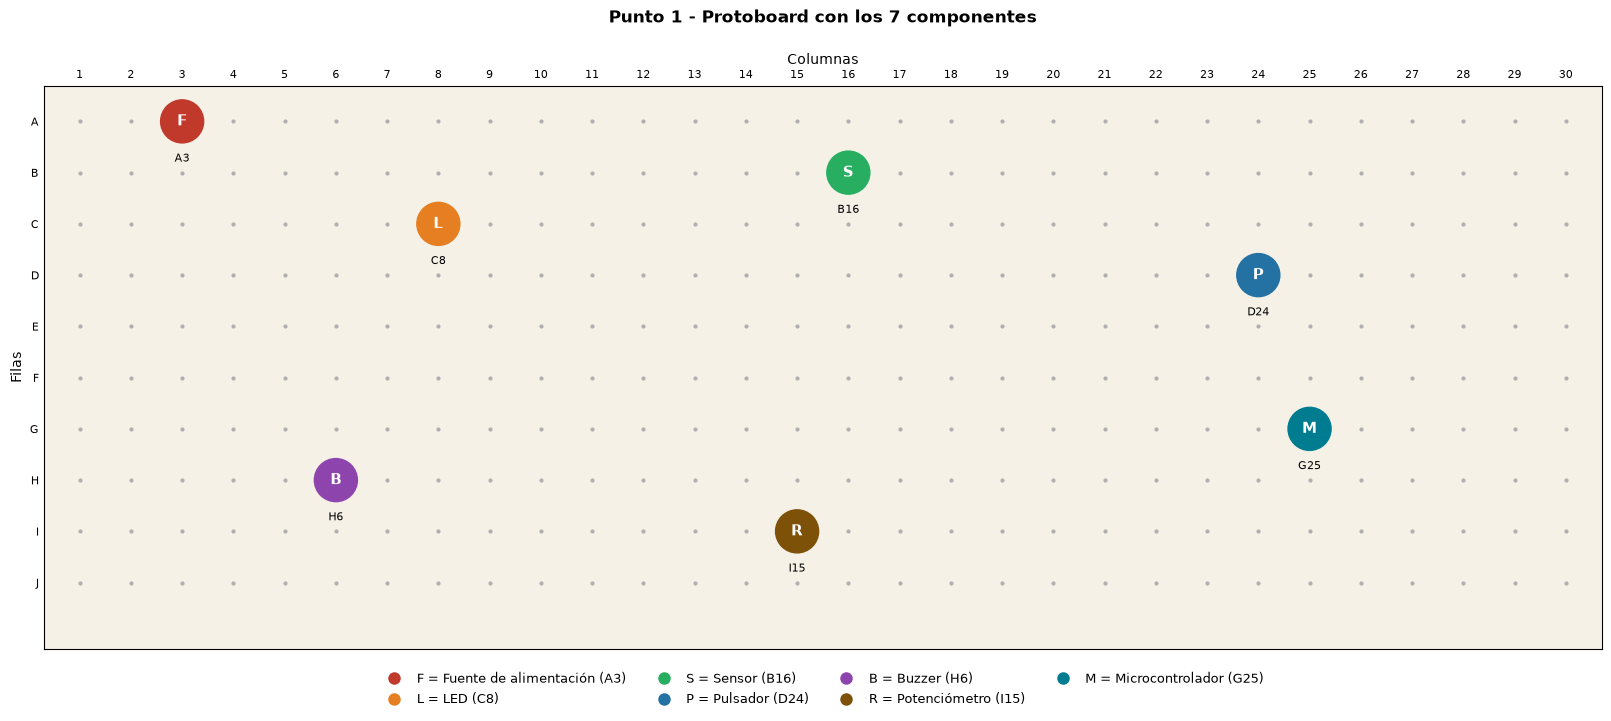

In [5]:
posiciones = dict(posiciones_iniciales)

fig, ax = plt.subplots(figsize=(16, 6.8), constrained_layout=True)
dibujar_protoboard(ax, posiciones, "Punto 1 - Protoboard con los 7 componentes")
poner_leyenda(ax, posiciones)
plt.show()

### Punto 2. Construcción del grafo

Cada componente es un vértice y cada par de componentes es una arista; su peso se calcula con las posiciones.

In [6]:
coordenadas, aristas = construir_grafo(posiciones)
componentes = list(posiciones.keys())

print("Vértices:", componentes)
print("Aristas:", len(aristas), "(n(n-1)/2 =", len(componentes) * (len(componentes) - 1) // 2, ")\n")

# Ejemplo del enunciado: F-L
cF = coordenadas["F"]
cL = coordenadas["L"]
print(f"F = {cF}, L = {cL} → distancia = |{cF[0]}-{cL[0]}| + |{cF[1]}-{cL[1]}| = {distancia(cF, cL)}\n")

# Matriz con la distancia entre cada par
peso_de = {}
for peso, u, v in aristas:
    peso_de[(u, v)] = peso
    peso_de[(v, u)] = peso

print("Distancia (cable necesario) entre cada par:")
print("     " + "".join(f"{v:>4}" for v in componentes))
for u in componentes:
    fila_texto = f"{u:>4} "
    for v in componentes:
        fila_texto += f"{(0 if u == v else peso_de[(u, v)]):>4}"
    print(fila_texto)

Vértices: ['F', 'L', 'S', 'P', 'B', 'R', 'M']
Aristas: 21 (n(n-1)/2 = 21 )

F = (3, 1), L = (8, 3) → distancia = |3-8| + |1-3| = 7

Distancia (cable necesario) entre cada par:
        F   L   S   P   B   R   M
   F    0   7  14  24  10  20  28
   L    7   0   9  17   7  13  21
   S   14   9   0  10  16   8  14
   P   24  17  10   0  22  14   4
   B   10   7  16  22   0  10  20
   R   20  13   8  14  10   0  12
   M   28  21  14   4  20  12   0


### Punto 3. Mostrar todas las posibles conexiones

F --------- 7 --------- L
F --------- 14 --------- S
F --------- 24 --------- P
F --------- 10 --------- B
F --------- 20 --------- R
F --------- 28 --------- M
L --------- 9 --------- S
L --------- 17 --------- P
L --------- 7 --------- B
L --------- 13 --------- R
L --------- 21 --------- M
S --------- 10 --------- P
S --------- 16 --------- B
S --------- 8 --------- R
S --------- 14 --------- M
P --------- 22 --------- B
P --------- 14 --------- R
P --------- 4 --------- M
B --------- 10 --------- R
B --------- 20 --------- M
R --------- 12 --------- M


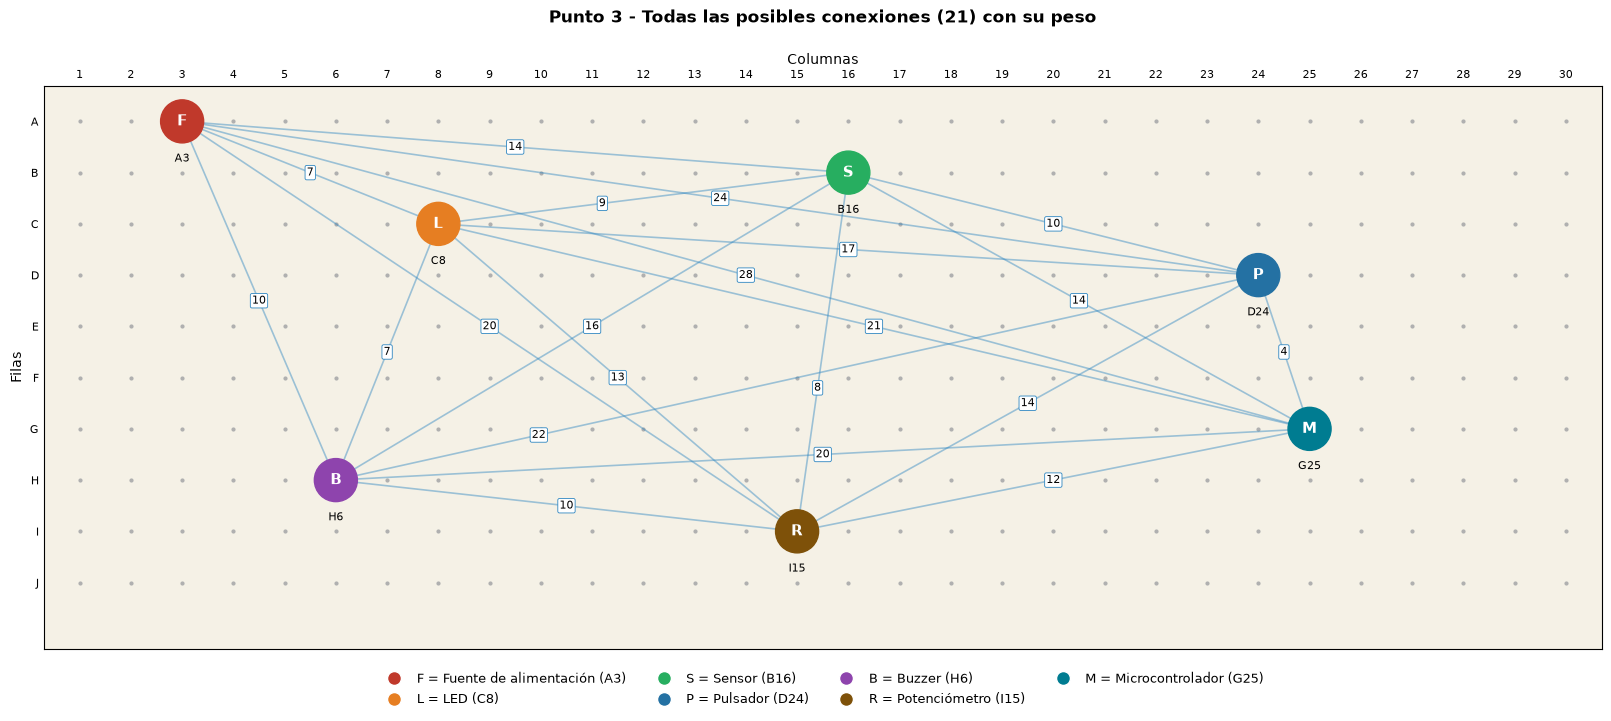

In [7]:
for peso, u, v in aristas:
    print(f"{u} --------- {peso} --------- {v}")

fig, ax = plt.subplots(figsize=(16, 7.2), constrained_layout=True)
dibujar_protoboard(ax, posiciones, f"Punto 3 - Todas las posibles conexiones ({len(aristas)}) con su peso")
dibujar_conexiones(ax, coordenadas, aristas)
poner_leyenda(ax, posiciones)
plt.show()

### Punto 4. Árbol de Expansión Mínimo (Kruskal)

Se muestra paso a paso cómo Kruskal ordena las conexiones, las revisa de menor a mayor peso y decide si cada una se **acepta** o se **rechaza** (si formaría un ciclo).

In [8]:
resultado = resolver(posiciones, mostrar_pasos=True)

print()
print(f"Aristas en el MST: {len(resultado['mst'])} (n - 1 = {len(componentes) - 1})")
print("Aristas revisadas por el algoritmo:", resultado["revisadas"], "de", len(aristas))

Aristas ordenadas de menor a mayor peso:
  P-M(4),  F-L(7),  L-B(7),  S-R(8),  L-S(9),  F-B(10),  S-P(10),  B-R(10),  R-M(12),  L-R(13),  F-S(14),  S-M(14),  P-R(14),  S-B(16),  L-P(17),  F-R(20),  B-M(20),  L-M(21),  P-B(22),  F-P(24),  F-M(28)

Paso  1: P-M (peso  4) → ACEPTADA   (cables: 1, total: 4)
Paso  2: F-L (peso  7) → ACEPTADA   (cables: 2, total: 11)
Paso  3: L-B (peso  7) → ACEPTADA   (cables: 3, total: 18)
Paso  4: S-R (peso  8) → ACEPTADA   (cables: 4, total: 26)
Paso  5: L-S (peso  9) → ACEPTADA   (cables: 5, total: 35)
Paso  6: F-B (peso 10) → rechazada (formaría un ciclo)
Paso  7: S-P (peso 10) → ACEPTADA   (cables: 6, total: 45)
Paso  8: ya hay 6 aristas (n - 1) → se termina.

Aristas en el MST: 6 (n - 1 = 6)
Aristas revisadas por el algoritmo: 7 de 21


### Punto 5. Mostrar el resultado

========== RESULTADO ==========
Componentes: F (A3), L (C8), S (B16), P (D24), B (H6), R (I15), M (G25)
Cable 1: P - M = 4
Cable 2: F - L = 7
Cable 3: L - B = 7
Cable 4: S - R = 8
Cable 5: L - S = 9
Cable 6: S - P = 10
Longitud total de cable: 45 unidades


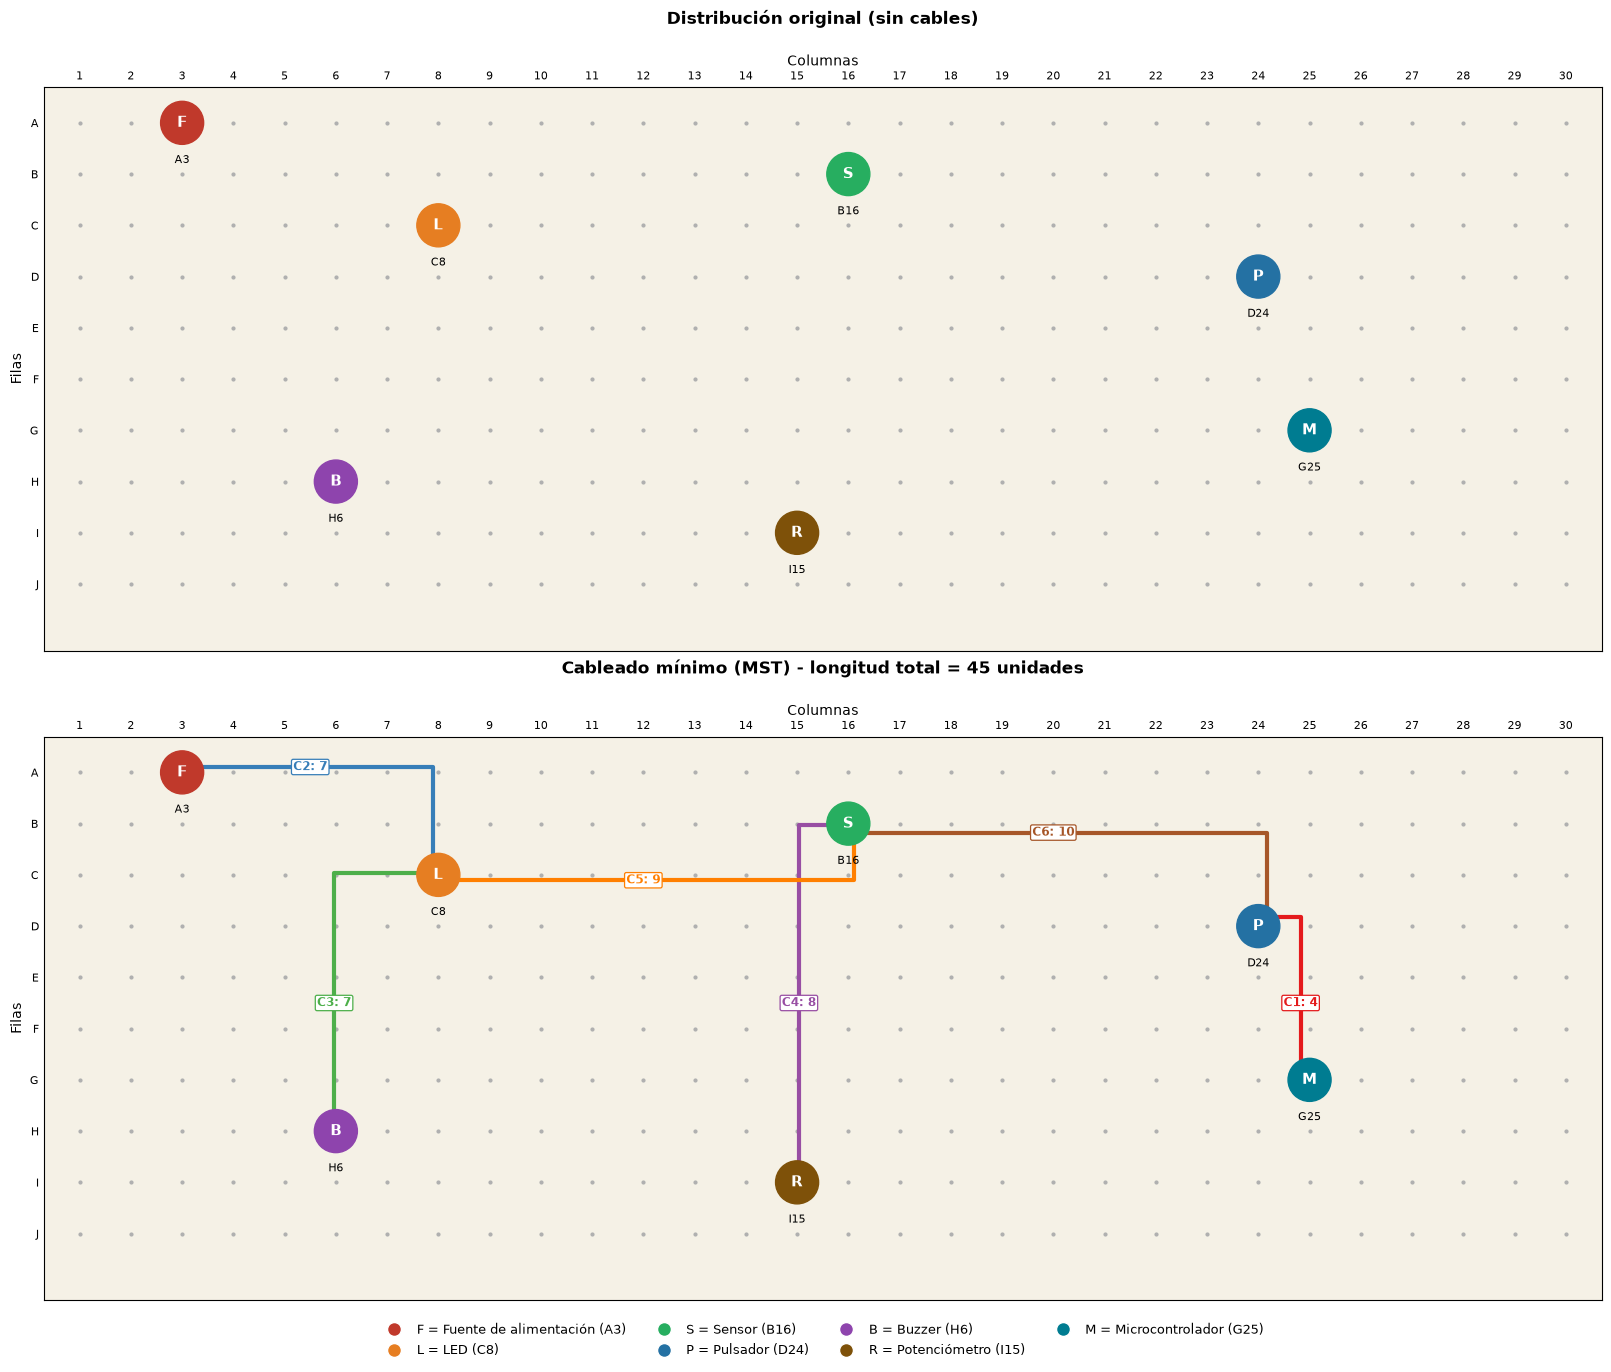

In [9]:
def mostrar_resultado(res, titulo):
    print(f"========== {titulo} ==========")
    print("Componentes:", ", ".join(f"{c} ({res['posiciones'][c]})" for c in res["componentes"]))
    for k, (peso, u, v) in enumerate(res["mst"], start=1):
        print(f"Cable {k}: {u} - {v} = {peso}")
    print(f"Longitud total de cable: {res['total']} unidades")


mostrar_resultado(resultado, "RESULTADO")

# Imagen final: distribución original arriba y cableado abajo para compararlas
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 13.5), constrained_layout=True)
dibujar_protoboard(ax1, posiciones, "Distribución original (sin cables)")
dibujar_protoboard(ax2, posiciones, f"Cableado mínimo (MST) - longitud total = {resultado['total']} unidades")
dibujar_cables(ax2, resultado["coordenadas"], resultado["mst"])
poner_leyenda(ax2, posiciones)
plt.show()

### Punto 6. Cambio en la distribución

El Buzzer cambia de posición: **H6 → J20**. Se actualiza la posición, se vuelve a construir el grafo (distancias nuevas), se ejecuta otra vez Kruskal y se genera de nuevo la gráfica.

Posición original del Buzzer: H6   →  nueva posición: J20

MST original - Longitud total: 45
MST después del cambio - Longitud total: 42

========== MST ORIGINAL ==========
Componentes: F (A3), L (C8), S (B16), P (D24), B (H6), R (I15), M (G25)
Cable 1: P - M = 4
Cable 2: F - L = 7
Cable 3: L - B = 7
Cable 4: S - R = 8
Cable 5: L - S = 9
Cable 6: S - P = 10
Longitud total de cable: 45 unidades

========== MST DESPUÉS DEL CAMBIO (Buzzer en J20) ==========
Componentes: F (A3), L (C8), S (B16), P (D24), B (J20), R (I15), M (G25)
Cable 1: P - M = 4
Cable 2: B - R = 6
Cable 3: F - L = 7
Cable 4: S - R = 8
Cable 5: B - M = 8
Cable 6: L - S = 9
Longitud total de cable: 42 unidades

¿Aumentó o disminuyó el cable? → DISMINUYÓ en 3 unidades (45 → 42).


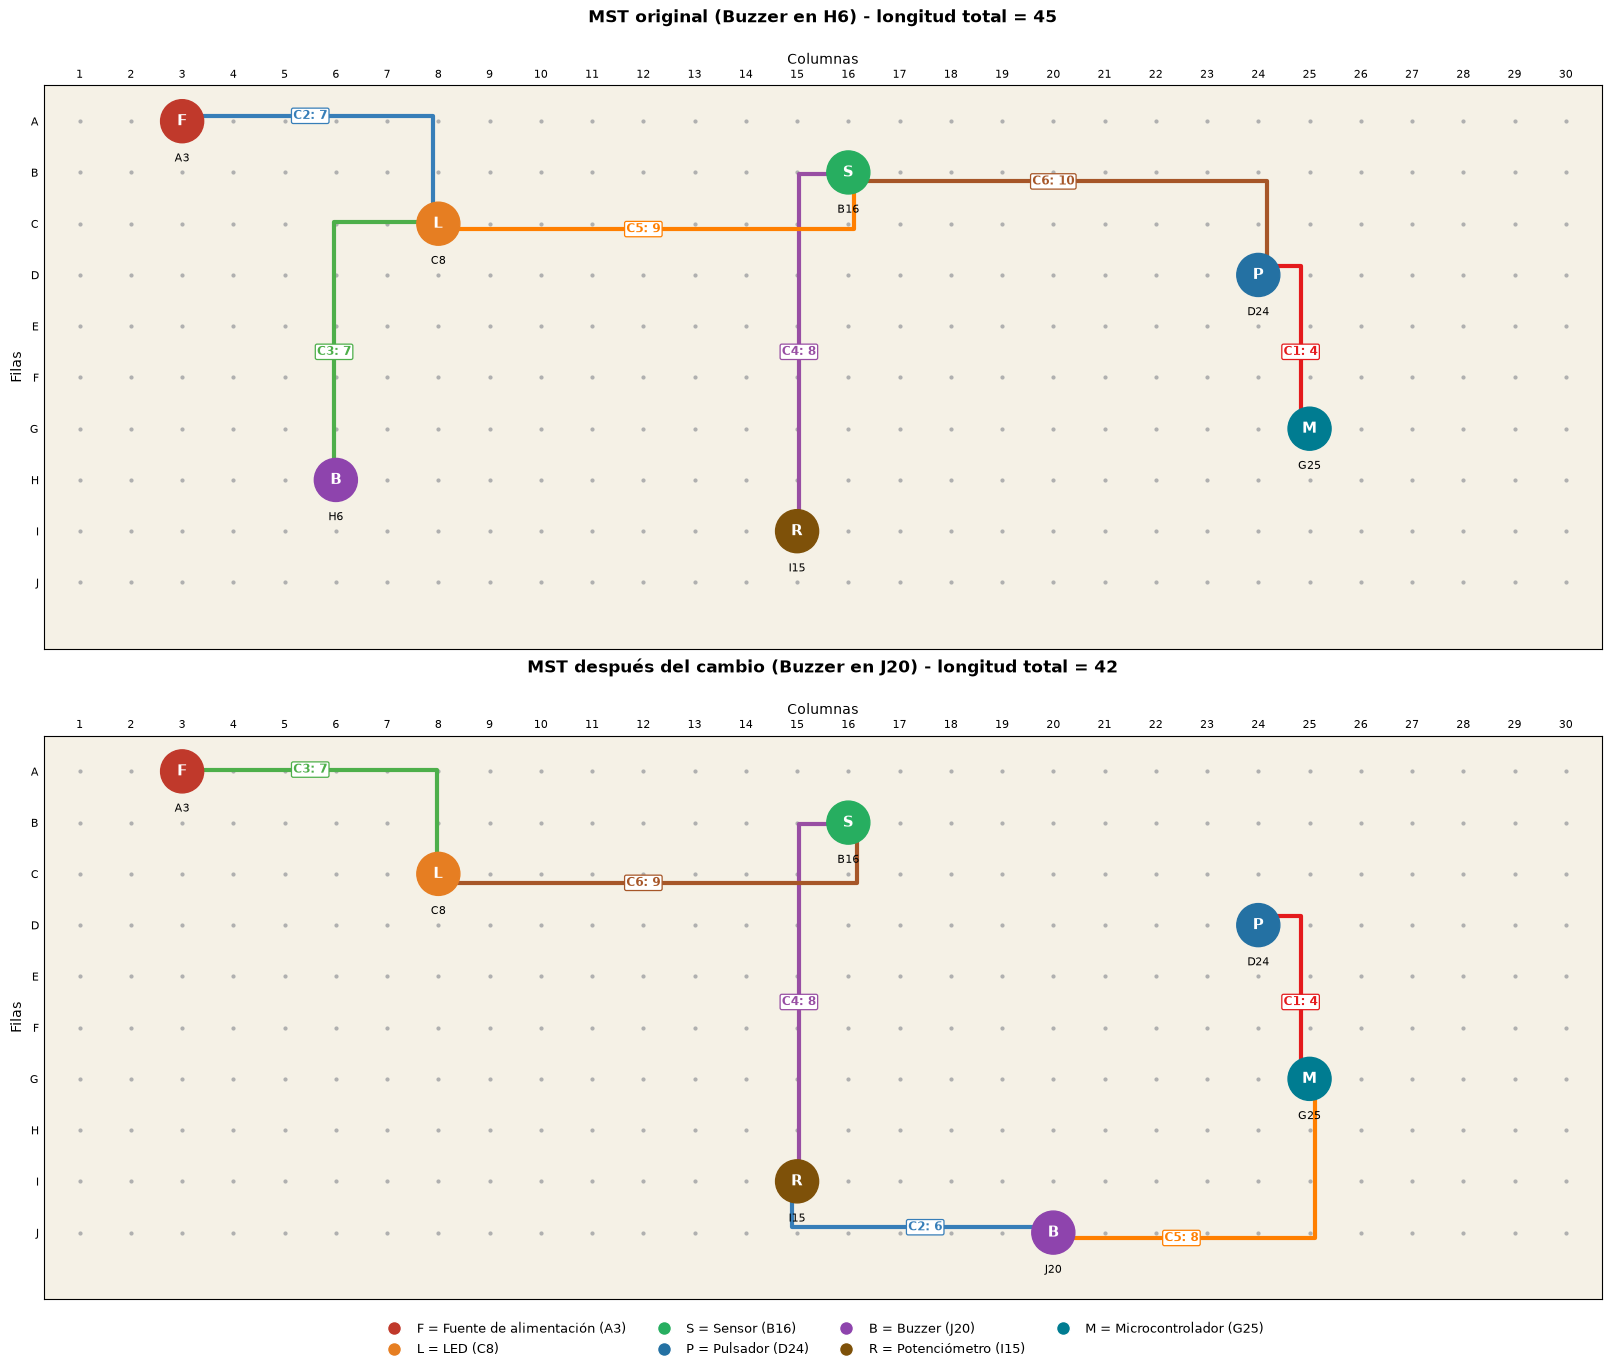

In [10]:
print("Posición original del Buzzer:", posiciones["B"], "  →  nueva posición: J20\n")

posiciones_nuevas = mover_componente(posiciones, "B", "J20")
resultado_nuevo = resolver(posiciones_nuevas)      # grafo y MST recalculados

print("MST original - Longitud total:", resultado["total"])
print("MST después del cambio - Longitud total:", resultado_nuevo["total"])
print()
mostrar_resultado(resultado, "MST ORIGINAL")
print()
mostrar_resultado(resultado_nuevo, "MST DESPUÉS DEL CAMBIO (Buzzer en J20)")

diferencia = resultado_nuevo["total"] - resultado["total"]
print()
if diferencia > 0:
    print(f"¿Aumentó o disminuyó el cable? → AUMENTÓ en {diferencia} unidades.")
elif diferencia < 0:
    print(f"¿Aumentó o disminuyó el cable? → DISMINUYÓ en {-diferencia} unidades ({resultado['total']} → {resultado_nuevo['total']}).")
else:
    print("¿Aumentó o disminuyó el cable? → Se mantuvo igual.")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 13.5), constrained_layout=True)
dibujar_protoboard(ax1, posiciones, f"MST original (Buzzer en H6) - longitud total = {resultado['total']}")
dibujar_cables(ax1, resultado["coordenadas"], resultado["mst"])
dibujar_protoboard(ax2, posiciones_nuevas, f"MST después del cambio (Buzzer en J20) - longitud total = {resultado_nuevo['total']}")
dibujar_cables(ax2, resultado_nuevo["coordenadas"], resultado_nuevo["mst"])
poner_leyenda(ax2, posiciones_nuevas)
plt.show()

**Conclusión del Punto 6:** al mover el Buzzer de **H6 a J20** la longitud total de cable **disminuyó de 45 a 42 unidades (−3)**.

*Explicación:* en H6 el Buzzer estaba lejos de casi todo (su cable más corto, B–L, medía 7). En J20 queda cerca del Potenciómetro (**B–R = 6**) y del Microcontrolador (**B–M = 8**), así que el MST usa esas dos conexiones y deja de usar B–L (7) y S–P (10): $4+6+7+8+8+9 = 42$ frente a $4+7+7+8+9+10 = 45$. Mover un componente no siempre reduce el cable: depende de qué tan cerca quede de los demás.

## 7) Tests aplicados **[15 pts]**

Se prueban con `assert` las conversiones de posiciones, las distancias, Kruskal (incluyendo una comparación contra **fuerza bruta** que revisa todos los árboles posibles) y el cambio de posición del Punto 6.

In [11]:
# ---------- Funciones auxiliares para los tests ----------
def da_error(tipo_error, funcion, *argumentos):
    """Devuelve True si la función lanza el error esperado."""
    try:
        funcion(*argumentos)
    except tipo_error:
        return True
    return False


def es_arbol(vertices, elegidas):
    """Revisa (sin usar los grupos de Kruskal) que las aristas sean n-1 y conecten todos los vértices."""
    if len(elegidas) != len(vertices) - 1:
        return False
    vecinos = {v: [] for v in vertices}
    for peso, u, v in elegidas:
        vecinos[u].append(v)
        vecinos[v].append(u)
    visitados = set()
    por_visitar = [vertices[0]]
    while por_visitar:
        actual = por_visitar.pop()
        if actual not in visitados:
            visitados.add(actual)
            por_visitar.extend(vecinos[actual])
    return len(visitados) == len(vertices)     # conexo con n-1 aristas → no hay ciclos


def peso_minimo_fuerza_bruta(vertices, aristas):
    """Prueba TODOS los grupos de n-1 aristas y devuelve el menor peso entre los que son árbol."""
    menor = None
    for grupo_aristas in combinations(aristas, len(vertices) - 1):
        if es_arbol(vertices, list(grupo_aristas)):
            suma = sum(a[0] for a in grupo_aristas)
            if menor is None or suma < menor:
                menor = suma
    return menor


# ---------- Test 1: posiciones ----------
assert posicion_a_coordenadas("A3") == (3, 1)        # F del enunciado
assert posicion_a_coordenadas("C8") == (8, 3)        # L del enunciado
assert posicion_a_coordenadas("H6") == (6, 8)
assert posicion_a_coordenadas("J20") == (20, 10)
assert posicion_a_coordenadas("A1") == (1, 1)        # esquina superior izquierda
assert posicion_a_coordenadas("J30") == (30, 10)     # esquina inferior derecha
for mala in ["K1", "A0", "A31", "", "A", "3A", "A-1", None, 5]:
    assert da_error(ValueError, posicion_a_coordenadas, mala), "debería rechazar " + str(mala)
assert da_error(ValueError, validar_posiciones, {"F": "A3", "L": "A3"})     # misma posición
print("✔ Test 1: conversión y validación de posiciones")

# ---------- Test 2: distancias y grafo ----------
assert distancia((3, 1), (8, 3)) == 7                # ejemplo del enunciado: F-L = 7
assert distancia((8, 3), (3, 1)) == 7                # simétrica
coord_test, aristas_test = construir_grafo(posiciones_iniciales)
assert len(aristas_test) == 21                       # 7·6/2
pesos = {}
for peso, u, v in aristas_test:
    pesos[u + v] = peso
assert pesos["FL"] == 7 and pesos["LS"] == 9 and pesos["SP"] == 10    # los ejemplos del enunciado
# algunos calculados a mano:
assert pesos["FS"] == 14 and pesos["PM"] == 4 and pesos["LB"] == 7 and pesos["SR"] == 8
assert pesos["BR"] == 10 and pesos["RM"] == 12 and pesos["FM"] == 28 and pesos["PB"] == 22
print("✔ Test 2: distancias y construcción del grafo (21 aristas)")

# ---------- Test 3: Kruskal en el caso del laboratorio ----------
res = resolver(posiciones_iniciales)
assert len(res["mst"]) == 6                          # n - 1 aristas
assert res["total"] == 45
assert res["total"] == sum(a[0] for a in res["mst"])
assert es_arbol(res["componentes"], res["mst"])      # conecta todo y no tiene ciclos
pesos_elegidos = [a[0] for a in res["mst"]]
assert pesos_elegidos == sorted(pesos_elegidos)      # se eligieron de menor a mayor
print("✔ Test 3: Kruskal en el laboratorio (6 cables, total 45)")

# ---------- Test 4: el resultado es el mínimo (fuerza bruta, C(21,6) = 54 264 combinaciones) ----------
assert peso_minimo_fuerza_bruta(res["componentes"], res["aristas"]) == 45
print("✔ Test 4: 45 es el mínimo según fuerza bruta")

# ---------- Test 5: grafos aleatorios pequeños (con muchos pesos repetidos) ----------
azar = random.Random(11)
for n in range(2, 7):
    for _ in range(25):
        vs = list(range(n))
        aris = []
        for i in range(n):
            for j in range(i + 1, n):
                aris.append((azar.randint(1, 9), i, j))
        mst, total, _ = kruskal(vs, aris)
        assert es_arbol(vs, mst)
        assert total == peso_minimo_fuerza_bruta(vs, aris)
print("✔ Test 5: 125 grafos aleatorios coinciden con fuerza bruta")

# ---------- Test 6: casos borde ----------
assert kruskal(["A"], []) == ([], 0, 0)                                  # un solo vértice
assert kruskal(["A", "B"], [(5, "A", "B")])[:2] == ([(5, "A", "B")], 5)  # dos vértices
assert da_error(ValueError, kruskal, ["A", "B", "C"], [(1, "A", "B")])   # grafo no conexo
mst, total, _ = kruskal(["A", "B", "C"], [(1, "A", "B"), (2, "B", "C"), (3, "A", "C")])
assert total == 3 and len(mst) == 2                  # el triángulo descarta la arista que forma el ciclo
print("✔ Test 6: casos borde (1 vértice, 2 vértices, no conexo, ciclo)")

# ---------- Test 7: cambio de posición (Punto 6) ----------
nuevas = mover_componente(posiciones_iniciales, "B", "J20")
assert nuevas["B"] == "J20"
assert posiciones_iniciales["B"] == "H6"             # la original no se modifica
assert da_error(ValueError, mover_componente, posiciones_iniciales, "B", "Z99")   # fuera de la protoboard
assert da_error(ValueError, mover_componente, posiciones_iniciales, "B", "A3")    # lugar ocupado por F
assert da_error(KeyError, mover_componente, posiciones_iniciales, "X", "J20")     # componente inexistente

antes = resolver(posiciones_iniciales)
despues = resolver(nuevas)
assert despues["coordenadas"]["B"] == (20, 10)       # el grafo se recalculó con la nueva posición
pesos_nuevos = {}
for peso, u, v in despues["aristas"]:
    pesos_nuevos[u + v] = peso
assert pesos_nuevos["FB"] == 26 and pesos_nuevos["LB"] == 19 and pesos_nuevos["SB"] == 12
assert pesos_nuevos["PB"] == 10 and pesos_nuevos["BR"] == 6 and pesos_nuevos["BM"] == 8
assert pesos_nuevos["FL"] == 7 and pesos_nuevos["PM"] == 4      # las que no tocan al Buzzer no cambian
assert antes["total"] == 45 and despues["total"] == 42
assert despues["total"] < antes["total"]             # el cable DISMINUYÓ
assert len(despues["mst"]) == 6 and es_arbol(despues["componentes"], despues["mst"])
assert peso_minimo_fuerza_bruta(despues["componentes"], despues["aristas"]) == 42
print("✔ Test 7: cambio del Buzzer H6 → J20 (total 45 → 42)")



✔ Test 1: conversión y validación de posiciones
✔ Test 2: distancias y construcción del grafo (21 aristas)
✔ Test 3: Kruskal en el laboratorio (6 cables, total 45)
✔ Test 4: 45 es el mínimo según fuerza bruta
✔ Test 5: 125 grafos aleatorios coinciden con fuerza bruta
✔ Test 6: casos borde (1 vértice, 2 vértices, no conexo, ciclo)
✔ Test 7: cambio del Buzzer H6 → J20 (total 45 → 42)
